In [1]:
# imports

import pandas as pd
from pathlib import Path
import os   
import random
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from pathlib import Path

In [2]:
# df = pd.read_csv('data_renamed.csv')
df = pd.read_csv('filtered_renamed.csv')


In [3]:
cols = [
    'Households with children under 6 with both parents working',
    'Households with children between 6-17 with both parents working',
    'Households with children under 6 with single mom'
]
# divide by total households and multiply by 100
for col in cols:
    df[col] = (df[col] / df['Number of Households']) * 100
    df[col] = df[col].round(2)

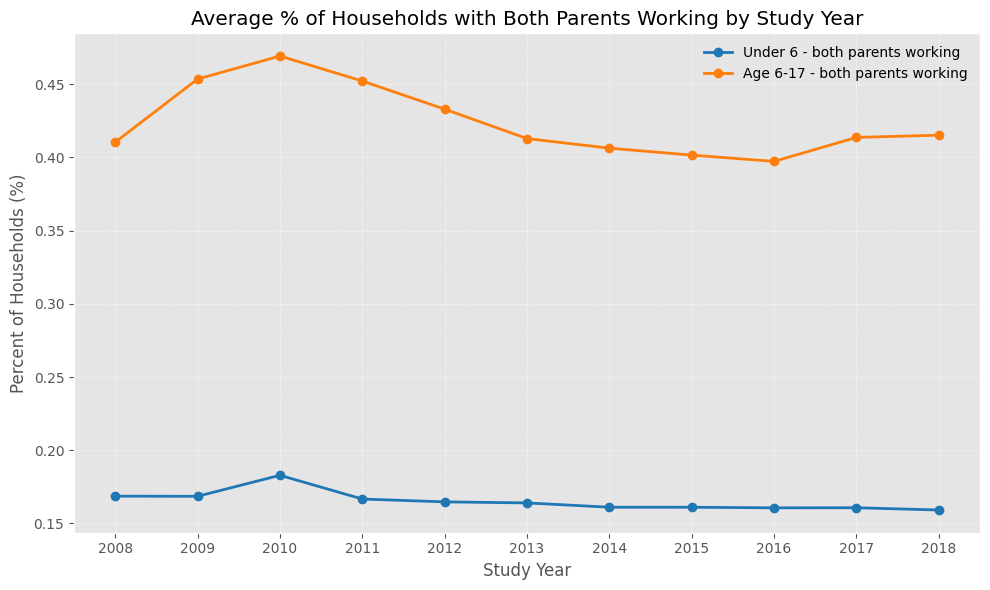

In [4]:
# Plot yearly averages for households with both parents working (under 6 and 6-17)
plt.style.use('ggplot')

cols = [
    'Households with children under 6 with both parents working',
    'Households with children between 6-17 with both parents working'
]

# check columns exist
missing = [c for c in cols if c not in df.columns]
if missing:
    print(f"Missing columns: {missing}")
else:
    # compute yearly means (coerce to numeric to be safe)
    df_year = (
        df.groupby('Study Year')[cols]
          .agg(lambda s: pd.to_numeric(s, errors='coerce').mean())
          .sort_index()
    )

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.plot(df_year.index, df_year[cols[0]], marker='o', linewidth=2, label='Under 6 - both parents working', color='tab:blue')
    ax.plot(df_year.index, df_year[cols[1]], marker='o', linewidth=2, label='Age 6-17 - both parents working', color='tab:orange')

    ax.set_title('Average % of Households with Both Parents Working by Study Year')
    ax.set_xlabel('Study Year')
    ax.set_ylabel('Percent of Households (%)')
    ax.set_xticks(df_year.index)
    ax.set_xticklabels(df_year.index.astype(str), rotation=0)
    ax.grid(True, linestyle=':', linewidth=0.6)
    ax.legend(frameon=False)

    plt.tight_layout()
    plt.show()

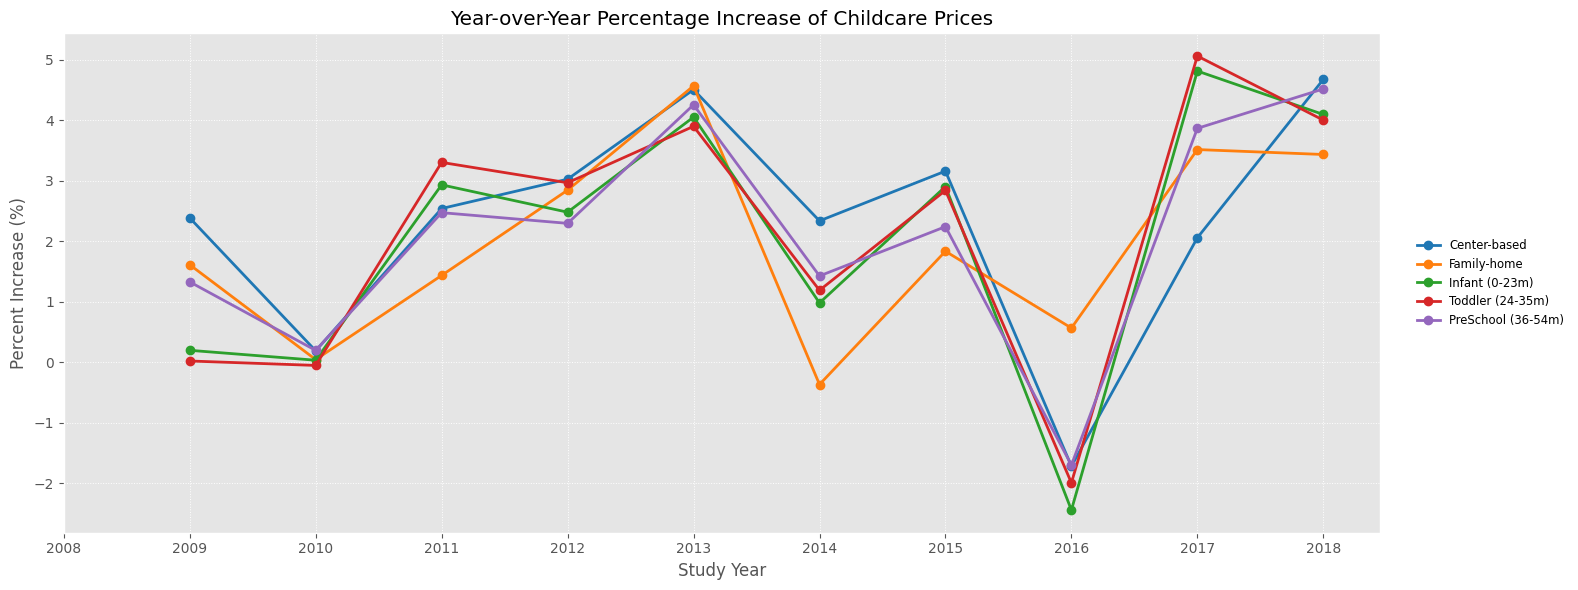

In [5]:
# Plot the year-over-year percent increase for all specified price columns (improved layout)
import textwrap

plt.style.use('ggplot')

price_cols = [
    'Weekly full-time median price charged for Center-Based Care for school-age children',
    'Weekly full-time median price charged for Family Childcare (home-based) for school-age children',
    'Full Time Median Price for Infant (0 to 23 months) Care',
    'Full Time Median Price for Toddler (24 to 35 months) Care',
    'Full Time Median Price for PreSchool (36 to 54 months) Care'
]

# keep only columns that exist in the dataframe
present_cols = [c for c in price_cols if c in df.columns]
if not present_cols:
    print("No price columns found. Available columns:", list(df.columns))
else:
    # compute year means and percent change
    df_mean_prices = df.groupby('Study Year')[present_cols].mean().sort_index()
    df_percent_increase = df_mean_prices.pct_change() * 100

    # short label helper
    short_map = {
        'Weekly full-time median price charged for Center-Based Care for school-age children': 'Center-based',
        'Weekly full-time median price charged for Family Childcare (home-based) for school-age children': 'Family-home',
        'Full Time Median Price for Infant (0 to 23 months) Care': 'Infant (0-23m)',
        'Full Time Median Price for Toddler (24 to 35 months) Care': 'Toddler (24-35m)',
        'Full Time Median Price for PreSchool (36 to 54 months) Care': 'PreSchool (36-54m)'
    }
    def short_label(name):
        return short_map.get(name, textwrap.shorten(name, width=30, placeholder='...'))

    # plotting
    fig, ax = plt.subplots(figsize=(14, 6))
    palette = sns.color_palette('tab10', n_colors=len(present_cols))

    for col, color in zip(df_percent_increase.columns, palette):
        ax.plot(df_percent_increase.index, df_percent_increase[col],
                marker='o', markersize=6, linewidth=2, color=color,
                label=short_label(col))

    ax.set_title('Year-over-Year Percentage Increase of Childcare Prices')
    ax.set_xlabel('Study Year')
    ax.set_ylabel('Percent Increase (%)')
    ax.grid(True, linestyle=':', linewidth=0.7)
    ax.set_xticks(df_percent_increase.index)
    ax.set_xticklabels(df_percent_increase.index.astype(str), rotation=0)

    # move plotting area left to make room for legend on the right
    box = ax.get_position()
    ax.set_position([box.x0, box.y0, box.width * 0.72, box.height])

    # place compact legend outside plot
    ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5),
              fontsize='small', frameon=False)

    plt.tight_layout()
    plt.show()

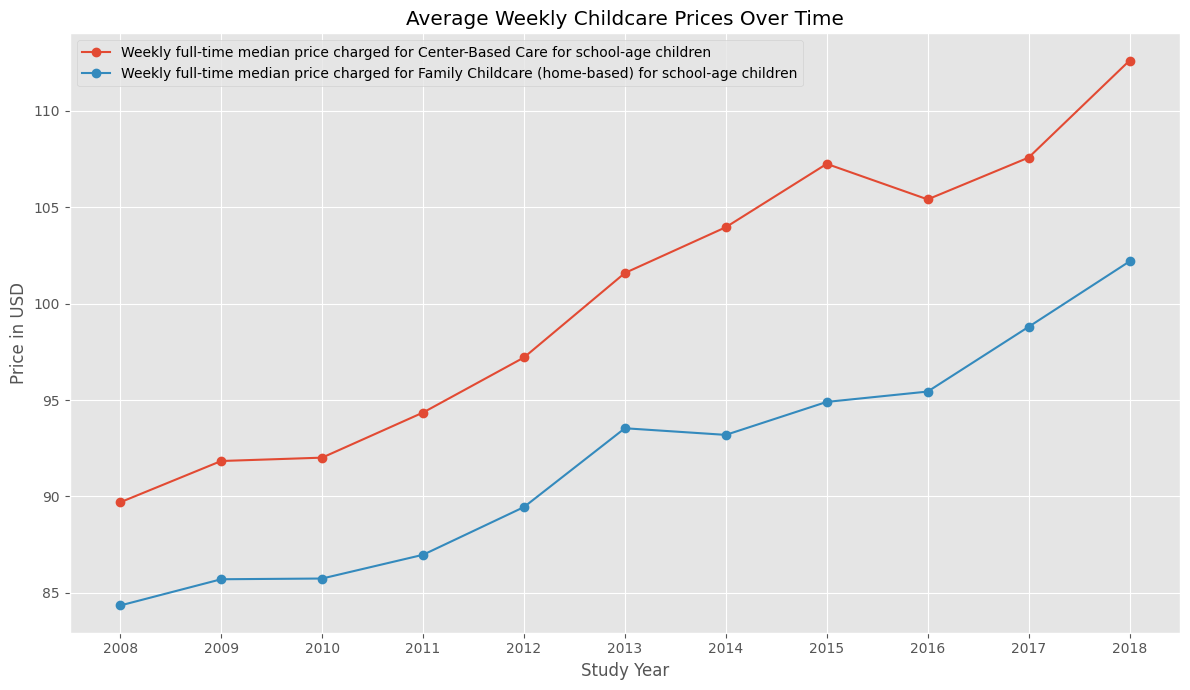

In [6]:
# Use a clean style for the plot
plt.style.use('ggplot')

# Group by 'Study Year' and calculate the mean for the specified columns
price_cols = [
    'Weekly full-time median price charged for Center-Based Care for school-age children',
    'Weekly full-time median price charged for Family Childcare (home-based) for school-age children'
    
]
df_mean_prices = df.groupby('Study Year')[price_cols].mean()

# Sort the data by year to ensure the line plot is chronological
df_mean_prices = df_mean_prices.sort_index()

# Create the line chart
plt.figure(figsize=(12, 7))

# Plot the center-based care prices
plt.plot(
    df_mean_prices.index,
    df_mean_prices['Weekly full-time median price charged for Center-Based Care for school-age children'],
    marker='o',
    label='Weekly full-time median price charged for Center-Based Care for school-age children'
)

# Plot the family childcare prices
plt.plot(
    df_mean_prices.index,
    df_mean_prices['Weekly full-time median price charged for Family Childcare (home-based) for school-age children'],
    marker='o',
    label='Weekly full-time median price charged for Family Childcare (home-based) for school-age children'
)

# Set the title and labels
plt.title('Average Weekly Childcare Prices Over Time')
plt.xlabel('Study Year')
plt.ylabel('Price in USD')
plt.grid(True)
plt.legend()
plt.xticks(df_mean_prices.index)
plt.tight_layout()
plt.show()

In [7]:
# create a median weekly income feature from "Median Household Income (2018 Dollars)"
src_col = 'Median Household Income'
new_col = 'Median Weekly Household Income'

if src_col in df.columns:
    # coerce non-numeric to NaN, then divide by 52 to get weekly income
    df[new_col] = pd.to_numeric(df[src_col], errors='coerce') / 52
    print(f"Created column: {new_col}")
    display(df[[src_col, new_col]].head())
else:
    print(f"Source column not found: {src_col}. Available columns: {list(df.columns)}")

Created column: Median Weekly Household Income


,Median Household Income,Median Weekly Household Income
0,50837.0,977.634615
1,51463.0,989.673077
2,53255.0,1024.134615
3,53899.0,1036.519231
4,53773.0,1034.096154


In [8]:
# create a new column that is the row-wise mean of the two specified price columns
cols = [
    'Weekly full-time median price charged for Center-Based Care for school-age children',
    'Weekly full-time median price charged for Family Childcare (home-based) for school-age children'
]
new_col = 'Weekly full-time median price charged (Center & Family mean)'

missing = [c for c in cols if c not in df.columns]
if missing:
    print(f"Missing columns: {missing}")
else:
    # coerce to numeric, then take the mean across the two columns (ignores NaNs)
    df[new_col] = df[cols].apply(pd.to_numeric, errors='coerce').mean(axis=1)
    print(f"Created column: {new_col}")
    display(df[cols + [new_col]].head())

Created column: Weekly full-time median price charged (Center & Family mean)


,Weekly full-time median price charged for Center-Based Care for school-age children,Weekly full-time median price charged for Family Childcare (home-based) for school-age children,Weekly full-time median price charged (Center & Family mean)
0,80.92,81.40,81.16
1,83.42,85.68,84.55
2,85.92,89.96,87.94
3,88.43,94.25,91.34
4,90.93,98.53,94.73


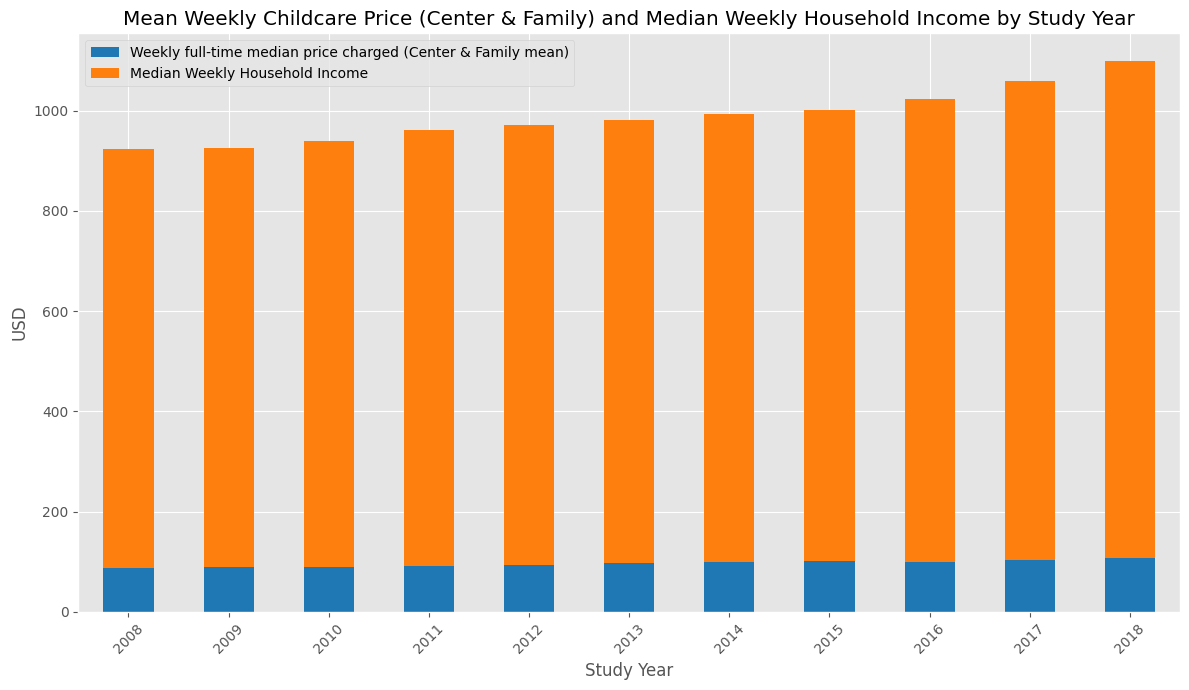

In [9]:
# Stacked bar chart of mean Weekly full-time median price (Center & Family mean)
# and Median Weekly Household Income by Study Year

plot_cols = [
    'Weekly full-time median price charged (Center & Family mean)',
    'Median Weekly Household Income'
]

missing = [c for c in plot_cols if c not in df.columns]
if missing:
    print(f"Missing columns: {missing}")
else:
    # Group by Study Year and take the mean of the two columns
    df_group = df.groupby('Study Year')[plot_cols].apply(lambda x: x.apply(pd.to_numeric, errors='coerce').mean())
    df_group = df_group.sort_index()

    # Create stacked bar chart
    ax = df_group.plot(
        kind='bar',
        stacked=True,
        figsize=(12, 7),
        color=['#1f77b4', '#ff7f0e']
    )

    ax.set_title('Mean Weekly Childcare Price (Center & Family) and Median Weekly Household Income by Study Year')
    ax.set_xlabel('Study Year')
    ax.set_ylabel('USD')
    ax.legend(title='')
    ax.set_xticklabels(df_group.index.astype(str), rotation=45)
    plt.tight_layout()
    plt.show()

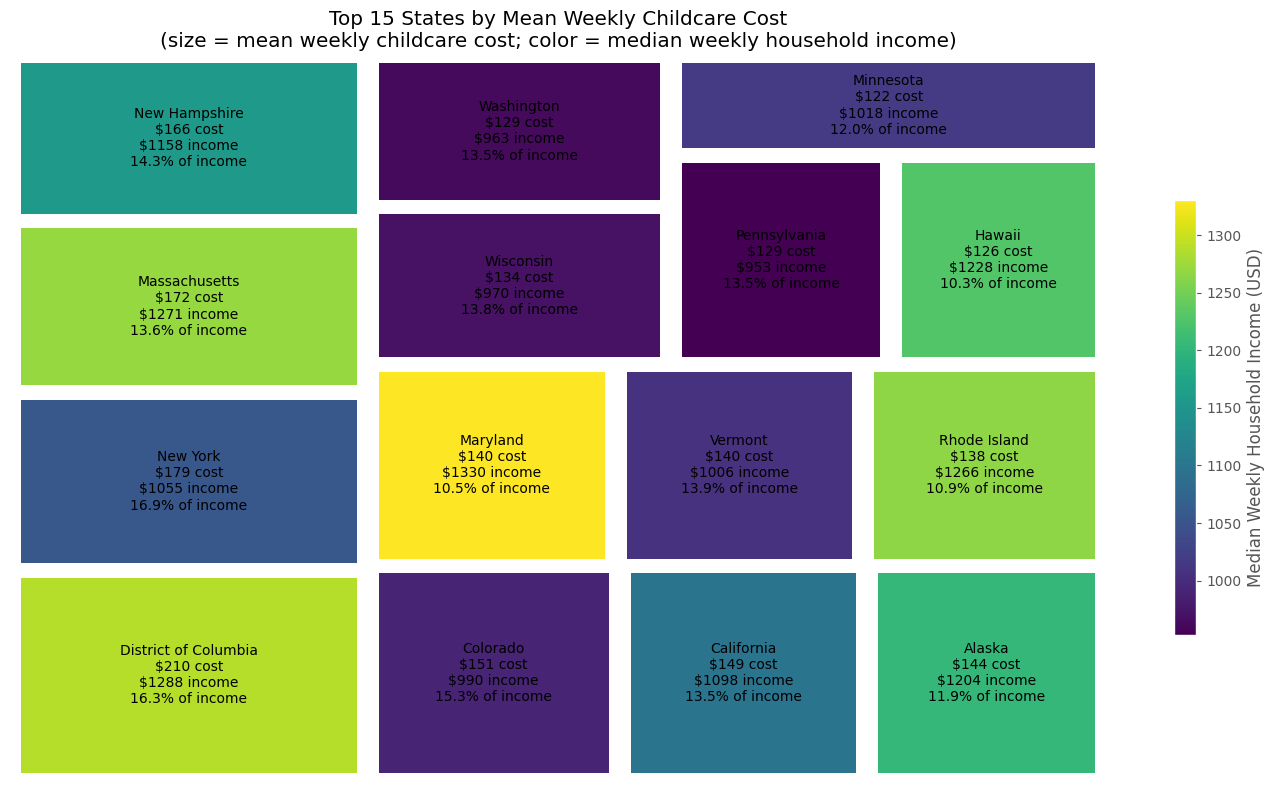

In [10]:

import squarify
import matplotlib as mpl


# columns already present in the notebook
cost_col = new_col  # 'Weekly full-time median price charged (Center & Family mean)'
income_col = 'Median Weekly Household Income'

# aggregate by state (mean), drop states with missing values
df_state = (
    df.groupby('State Name')[[cost_col, income_col]]
      .apply(lambda x: x.apply(pd.to_numeric, errors='coerce').mean())
      .reset_index()
      .dropna(subset=[cost_col, income_col])
)

# create ratio and sort by cost, take top N for readability
df_state['cost_to_income_ratio'] = df_state[cost_col] / df_state[income_col]
top_n = 15
top = df_state.sort_values(by=cost_col, ascending=False).head(top_n)

# prepare sizes, colors and labels
sizes = top[cost_col].tolist()
cmap = plt.get_cmap('viridis')
# use matplotlib.colors.Normalize via the mpl namespace (plt.colors doesn't exist)
norm = mpl.colors.Normalize(vmin=top[income_col].min(), vmax=top[income_col].max())
colors = [cmap(norm(v)) for v in top[income_col]]

labels = [
    f"{s}\n${c:.0f} cost\n${i:.0f} income\n{(c/i):.1%} of income"
    for s, c, i in zip(top['State Name'], top[cost_col], top[income_col])
]

# plot treemap using explicit Figure and Axes so we can attach the colorbar to the same Axes
fig, treemap_ax = plt.subplots(figsize=(14, 8))
squarify.plot(sizes=sizes, label=labels, color=colors, pad=True, text_kwargs={'fontsize':10}, ax=treemap_ax)
treemap_ax.set_title(f"Top {top_n} States by Mean Weekly Childcare Cost\n(size = mean weekly childcare cost; color = median weekly household income)")
treemap_ax.axis('off')

# add colorbar for income - attach it to the same figure/axes to avoid the "unable to determine Axes" error
sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array(top[income_col].values)
cbar = fig.colorbar(sm, ax=treemap_ax, orientation='vertical', shrink=0.6)
cbar.set_label('Median Weekly Household Income (USD)')

plt.tight_layout()
plt.show()

In [11]:
# create "Childcare Cost As Percent of Weekly Income" as percent (rounded to 2 decimals)
col_name = 'Childcare Cost As Percent of Weekly Income'

num = pd.to_numeric(df[new_col], errors='coerce')
den = pd.to_numeric(df[income_col], errors='coerce')

ratio = (num / den) * 100
ratio = ratio.replace([float('inf'), float('-inf')], pd.NA).round(2)

df[col_name] = ratio

# show a preview
display(df[[new_col, income_col, col_name]].head())

,Weekly full-time median price charged (Center & Family mean),Median Weekly Household Income,Childcare Cost As Percent of Weekly Income
0,81.16,977.634615,8.30
1,84.55,989.673077,8.54
2,87.94,1024.134615,8.59
3,91.34,1036.519231,8.81
4,94.73,1034.096154,9.16


In [12]:
for col in df.columns:
    print(col)

State Name
County Name
Study Year
Number of Households
Weekly full-time median price charged for Center-Based Care for school-age children
Weekly full-time median price charged for Family Childcare (home-based) for school-age children
Unemployment 16 & Older
Female Unemployment 16 & Older
Male Unemployment 16 & Older
Total Population
Unemployment 20-64 Year Olds
Poverty Rate Families
Median Household Income
Whites
Blacks
Hispanic
Asian
Households with children under 6 with both parents working
Households with children between 6-17 with both parents working
Households with children under 6 with single mom
Full Time Median Price for Infant (0 to 23 months) Care
Full Time Median Price for Toddler (24 to 35 months) Care
Full Time Median Price for PreSchool (36 to 54 months) Care
Male Median Earnings
Female Median Earnings
Median Childcare Costs for Children 0-23 months
Median Childcare Costs for Children 24-47 months
Median Childcare Costs for Children 48-54 months
Median Weekly Household 

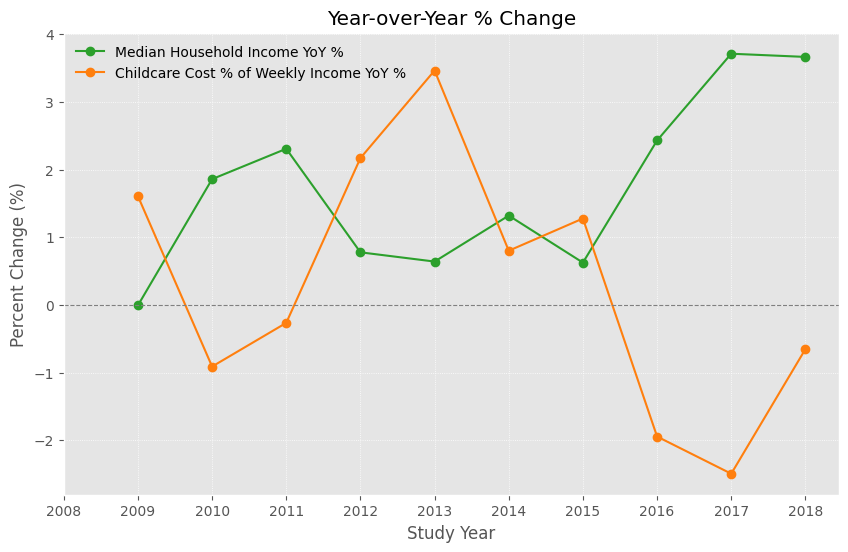

In [13]:
# Plot YoY % change: Median Household Income (2018 Dollars) vs Childcare Cost As Percent of Weekly Income

# use existing column name variables where available
income_col = src_col  # 'Median Household Income (2018 Dollars)'
childcare_pct_col = col_name  # 'Childcare Cost As Percent of Weekly Income'

# check required columns
required = [income_col, childcare_pct_col, 'Study Year']
missing = [c for c in required if c not in df.columns]
if missing:
    print("Missing columns:", missing)
else:
    # yearly means (coerce numeric)
    df_year = (
        df.groupby('Study Year')[[income_col, childcare_pct_col]]
          .agg(lambda s: pd.to_numeric(s, errors='coerce').mean())
          .sort_index()
    )

    # year-over-year percent change
    df_yoy = df_year.pct_change() * 100

    # prepare plotting
    fig, ax = plt.subplots(figsize=(10, 6)) # Create a single figure and axes object

    ax.plot(df_yoy.index, df_yoy[income_col], marker='o', label='Median Household Income YoY %', color='tab:green')
    ax.plot(df_yoy.index, df_yoy[childcare_pct_col], marker='o', label='Childcare Cost % of Weekly Income YoY %', color='tab:orange')
    ax.axhline(0, color='gray', linewidth=0.8, linestyle='--')
    ax.set_title('Year-over-Year % Change')
    ax.set_xlabel('Study Year')
    ax.set_ylabel('Percent Change (%)')
    ax.set_xticks(df_yoy.index)
    ax.set_xticklabels(df_yoy.index.astype(str), rotation=0)
    ax.grid(True, linestyle=':', linewidth=0.6)
    ax.legend(frameon=False)




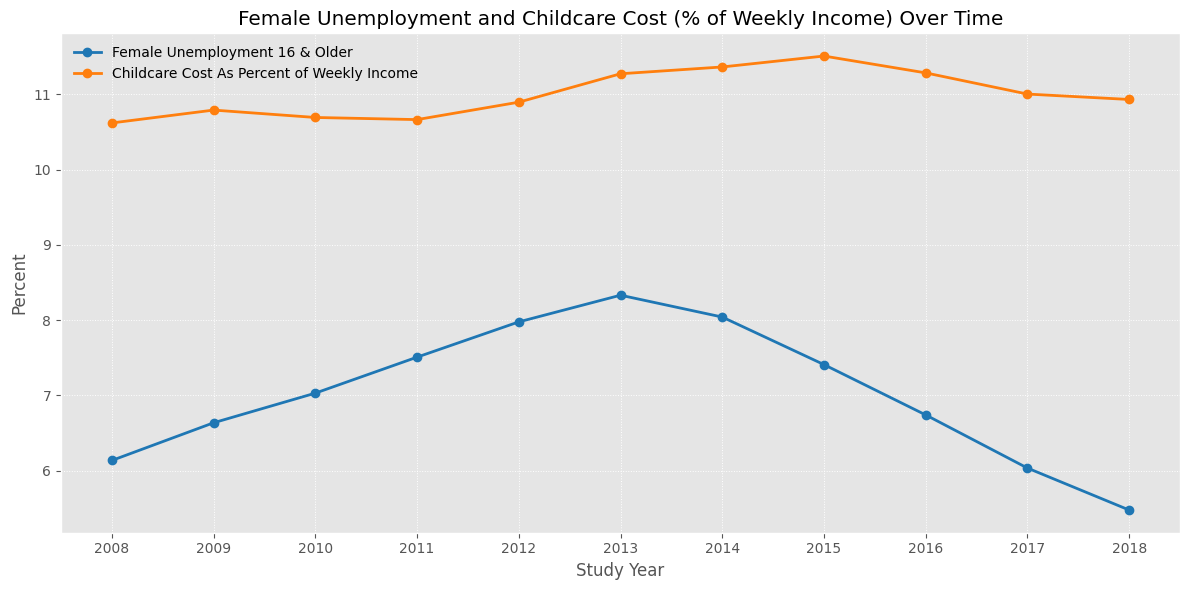

In [14]:
# Plot Female Unemployment and Childcare Cost (% of Weekly Income) over time

plt.style.use('ggplot')

# define the columns to plot (use existing notebook variables when available)
# Female unemployment column exists in the dataframe as 'Female Unemployment 16 & Older'
x_col = 'Female Unemployment 16 & Older'
# use the previously created column name for childcare percent-of-income
y_col = col_name

# ensure the required columns exist
required = [x_col, y_col, 'Study Year']
missing = [c for c in required if c not in df.columns]
if missing:
    print("Missing columns:", missing)
else:
    # compute yearly means (coerce to numeric to avoid issues)
    df_time = (
        df.groupby('Study Year')[[x_col, y_col]]
          .agg(lambda s: pd.to_numeric(s, errors='coerce').mean())
          .sort_index()
    )

    fig, ax = plt.subplots(figsize=(12, 6))
    ax.plot(df_time.index, df_time[x_col], marker='o', linewidth=2, label=x_col, color='tab:blue')
    ax.plot(df_time.index, df_time[y_col], marker='o', linewidth=2, label=y_col, color='tab:orange')

    ax.set_title('Female Unemployment and Childcare Cost (% of Weekly Income) Over Time')
    ax.set_xlabel('Study Year')
    ax.set_ylabel('Percent')
    ax.set_xticks(df_time.index)
    ax.set_xticklabels(df_time.index.astype(str), rotation=0)
    ax.grid(True, linestyle=':', linewidth=0.7)
    ax.legend(loc='best', frameon=False)

    plt.tight_layout()
    plt.show()

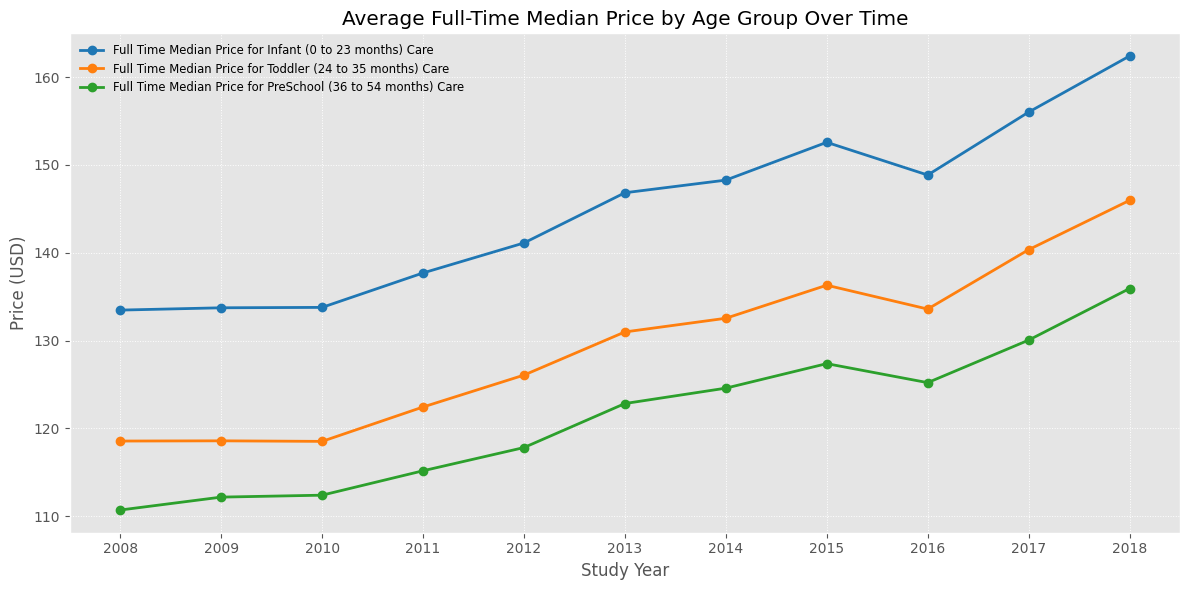

In [15]:
# Line chart: Infant, Toddler, PreSchool full-time median prices over Study Year

plt.style.use('ggplot')

cols = [
    'Full Time Median Price for Infant (0 to 23 months) Care',
    'Full Time Median Price for Toddler (24 to 35 months) Care',
    'Full Time Median Price for PreSchool (36 to 54 months) Care'
]

missing = [c for c in cols if c not in df.columns]
if missing:
    print("Missing columns:", missing)
else:
    # compute yearly means (coerce to numeric to be safe) and sort by year
    df_age_mean = (
        df.groupby('Study Year')[cols]
          .agg(lambda s: pd.to_numeric(s, errors='coerce').mean())
          .sort_index()
    )

    fig, ax = plt.subplots(figsize=(12, 6))
    colors = sns.color_palette('tab10', n_colors=3)

    for col_name, color in zip(df_age_mean.columns, colors):
        ax.plot(df_age_mean.index, df_age_mean[col_name],
                marker='o', linewidth=2, label=col_name, color=color)

    ax.set_title('Average Full-Time Median Price by Age Group Over Time')
    ax.set_xlabel('Study Year')
    ax.set_ylabel('Price (USD)')
    ax.set_xticks(df_age_mean.index)
    ax.set_xticklabels(df_age_mean.index.astype(str), rotation=0)
    ax.grid(True, linestyle=':', linewidth=0.7)
    ax.legend(frameon=False, fontsize='small')
    plt.tight_layout()
    plt.show()

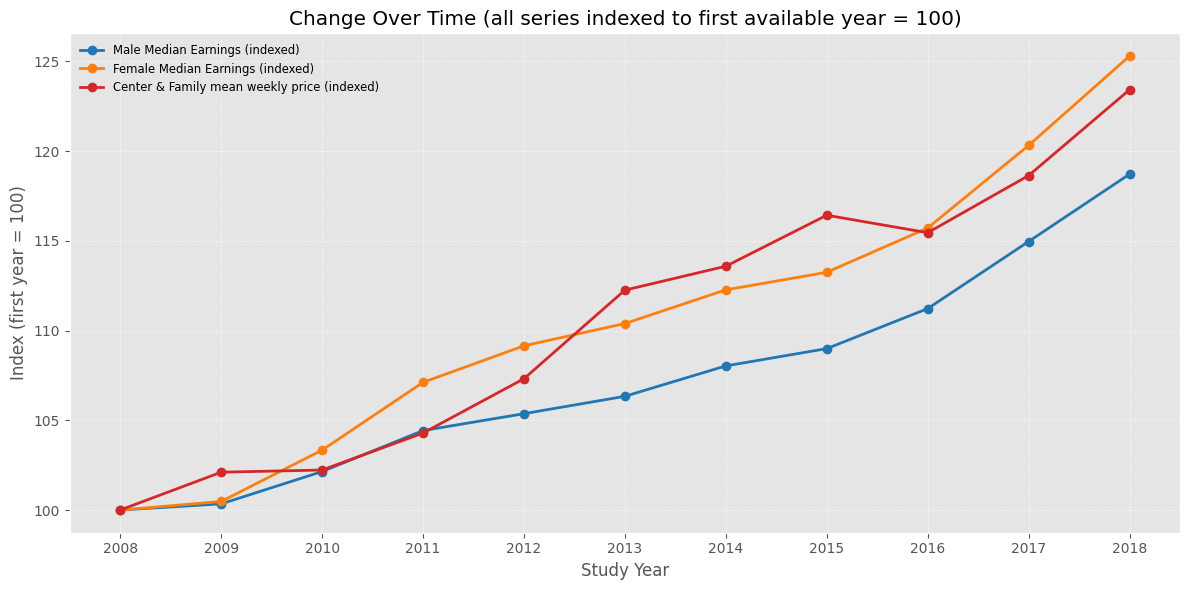

In [16]:
# Single-plot: Male & Female Median Earnings (indexed) and Center&Family mean weekly price (also indexed)
plt.style.use('ggplot')

earn_cols = ['Male Median Earnings', 'Female Median Earnings']
cost_col = 'Weekly full-time median price charged (Center & Family mean)'

# ensure earnings series (compute if not available)
if 'df_earn_indexed' not in globals():
    if any(c not in df.columns for c in earn_cols):
        print("Missing earnings columns:", [c for c in earn_cols if c not in df.columns])
    else:
        df_earn = df.groupby('Study Year')[earn_cols].agg(lambda s: pd.to_numeric(s, errors='coerce').mean()).sort_index()
        df_earn_clean = df_earn.dropna(how='all')
        first_vals = df_earn_clean.iloc[0]
        df_earn_indexed = (df_earn_clean / first_vals) * 100

# ensure cost series (compute yearly mean if not available)
if 'df_cost' not in globals():
    if cost_col in df.columns:
        df_cost = df.groupby('Study Year')[[cost_col]].agg(lambda s: pd.to_numeric(s, errors='coerce').mean()).sort_index()
    else:
        df_cost = None

if (('df_earn_indexed' in globals()) and (df_cost is not None) and (not df_earn_indexed.empty) and (not df_cost.empty)):
    # index the cost series to its first available year so all three lines use same index baseline (first year = 100)
    cost_series = df_cost[cost_col].dropna()
    if cost_series.empty:
        print("Cost series empty after dropping NA.")
    else:
        cost_first = cost_series.iloc[0]
        cost_indexed = (cost_series / cost_first) * 100
        # combine into one dataframe (align on Study Year)
        df_plot = pd.concat([df_earn_indexed, cost_indexed.rename('Center&Family mean (indexed)')], axis=1).sort_index()

        fig, ax_single = plt.subplots(figsize=(12, 6))
        ax_single.plot(df_plot.index, df_plot['Male Median Earnings'], marker='o', linewidth=2, label='Male Median Earnings (indexed)', color='tab:blue')
        ax_single.plot(df_plot.index, df_plot['Female Median Earnings'], marker='o', linewidth=2, label='Female Median Earnings (indexed)', color='tab:orange')
        ax_single.plot(df_plot.index, df_plot['Center&Family mean (indexed)'], marker='o', linewidth=2, label='Center & Family mean weekly price (indexed)', color='tab:red')

        ax_single.set_title('Change Over Time (all series indexed to first available year = 100)')
        ax_single.set_xlabel('Study Year')
        ax_single.set_ylabel('Index (first year = 100)')
        ax_single.set_xticks(df_plot.index)
        ax_single.set_xticklabels(df_plot.index.astype(str), rotation=0)
        ax_single.grid(True, linestyle=':', linewidth=0.6)
        ax_single.legend(frameon=False, fontsize='small')
        plt.tight_layout()
        plt.show()
else:
    print("Required data for plotting not available.")


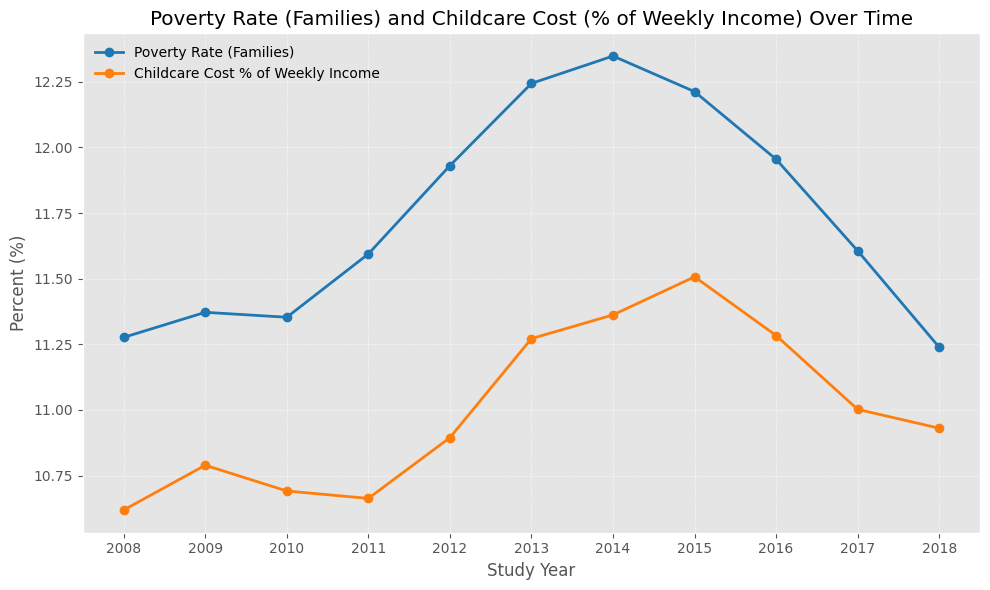

In [17]:
# Line chart: Poverty Rate Families and Childcare Cost As Percent of Weekly Income over time

plt.style.use('ggplot')

cols = ['Poverty Rate Families', childcare_pct_col]  # childcare_pct_col defined earlier

missing = [c for c in cols if c not in df.columns]
if missing:
    print("Missing columns:", missing)
else:
    # compute yearly means (coerce to numeric) and sort by year
    df_year = (
        df.groupby('Study Year')[cols]
          .agg(lambda s: pd.to_numeric(s, errors='coerce').mean())
          .sort_index()
    )

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.plot(df_year.index, df_year['Poverty Rate Families'], marker='o', linewidth=2,
            label='Poverty Rate (Families)', color='tab:blue')
    ax.plot(df_year.index, df_year[childcare_pct_col], marker='o', linewidth=2,
            label='Childcare Cost % of Weekly Income', color='tab:orange')

    ax.set_title('Poverty Rate (Families) and Childcare Cost (% of Weekly Income) Over Time')
    ax.set_xlabel('Study Year')
    ax.set_ylabel('Percent (%)')
    ax.set_xticks(df_year.index)
    ax.set_xticklabels(df_year.index.astype(str), rotation=0)
    ax.grid(True, linestyle=':', linewidth=0.6)
    ax.legend(frameon=False)

    plt.tight_layout()
    plt.show()

In [18]:
corr_matrix_features = [
    
    'Childcare Cost As Percent of Weekly Income',
    'Poverty Rate Families','Female Median Earnings','Female Unemployment 16 & Older',
    'Households with children under 6 with both parents working','Male Unemployment 16 & Older',
    'Number of Households'
]


In [19]:
# print column names with index
print(f"Total columns: {len(df.columns)}")
for i, col in enumerate(df.columns, start=1):
    print(f"{i:2d}. {col}")

Total columns: 31
 1. State Name
 2. County Name
 3. Study Year
 4. Number of Households
 5. Weekly full-time median price charged for Center-Based Care for school-age children
 6. Weekly full-time median price charged for Family Childcare (home-based) for school-age children
 7. Unemployment 16 & Older
 8. Female Unemployment 16 & Older
 9. Male Unemployment 16 & Older
10. Total Population
11. Unemployment 20-64 Year Olds
12. Poverty Rate Families
13. Median Household Income
14. Whites
15. Blacks
16. Hispanic
17. Asian
18. Households with children under 6 with both parents working
19. Households with children between 6-17 with both parents working
20. Households with children under 6 with single mom
21. Full Time Median Price for Infant (0 to 23 months) Care
22. Full Time Median Price for Toddler (24 to 35 months) Care
23. Full Time Median Price for PreSchool (36 to 54 months) Care
24. Male Median Earnings
25. Female Median Earnings
26. Median Childcare Costs for Children 0-23 months


Dropped 10933 rows with NA; using 23634 rows for correlation.


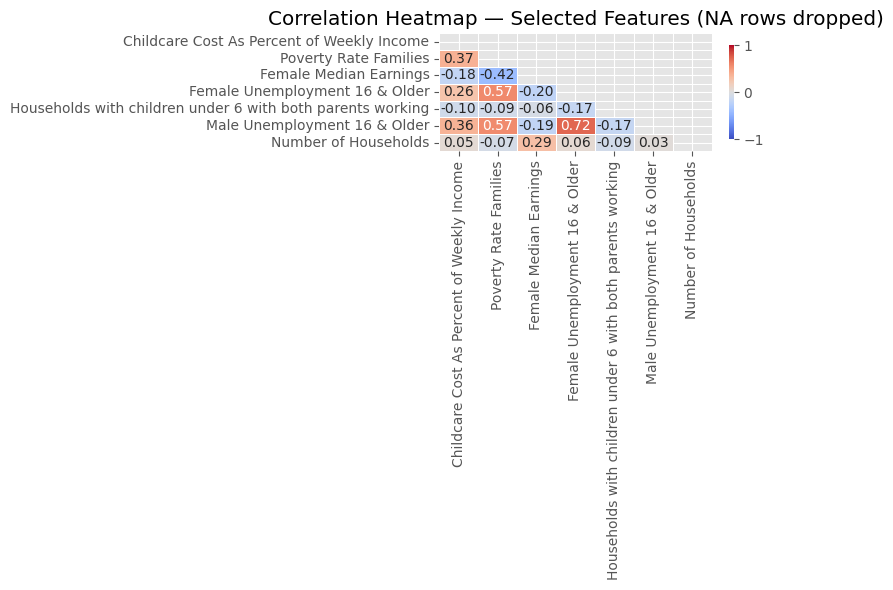

In [20]:
import numpy as np

# prepare the columns from the notebook variable `corr_matrix_features`
cols = [c for c in corr_matrix_features if c in df.columns]
missing = [c for c in corr_matrix_features if c not in df.columns]

if missing:
    print("Missing columns for correlation heatmap:", missing)

if not cols:
    print("No valid columns available for correlation heatmap.")
else:
    # coerce to numeric
    df_num = df[cols].apply(pd.to_numeric, errors='coerce')

    # drop rows with any NA in the selected columns (user requested)
    n_before = len(df_num)
    df_num = df_num.dropna()
    n_after = len(df_num)
    if df_num.empty:
        print(f"No rows remain after dropping NA (dropped {n_before} rows). Cannot compute correlation.")
    else:
        print(f"Dropped {n_before - n_after} rows with NA; using {n_after} rows for correlation.")

        # compute correlation
        corr = df_num.corr()

        # plot heatmap (mask upper triangle for cleaner view)
        plt.style.use('ggplot')
        fig, ax_heat = plt.subplots(figsize=(8, 6))
        mask = np.triu(np.ones_like(corr, dtype=bool))

        sns.heatmap(
            corr,
            mask=mask,
            annot=True,
            fmt='.2f',
            cmap='coolwarm',
            vmin=-1,
            vmax=1,
            center=0,
            linewidths=0.5,
            cbar_kws={"shrink": 0.8},
            ax=ax_heat
        )

        ax_heat.set_title('Correlation Heatmap — Selected Features (NA rows dropped)')
        plt.tight_layout()
        plt.show()

Correlation with 'Childcare Cost As Percent of Weekly Income':
Weekly full-time median price charged (Center & Family mean)                                       0.548848
Weekly full-time median price charged for Center-Based Care for school-age children                0.535187
Weekly full-time median price charged for Family Childcare (home-based) for school-age children    0.518765
Poverty Rate Families                                                                              0.374441
Male Unemployment 16 & Older                                                                       0.359950
Unemployment 20-64 Year Olds                                                                       0.340893
Unemployment 16 & Older                                                                            0.337592
Full Time Median Price for PreSchool (36 to 54 months) Care                                        0.270743
Median Childcare Costs for Children 48-54 months                         

/var/folders/11/dxk146610qn60jn0f0xly1800000gn/T/ipykernel_22538/157916905.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


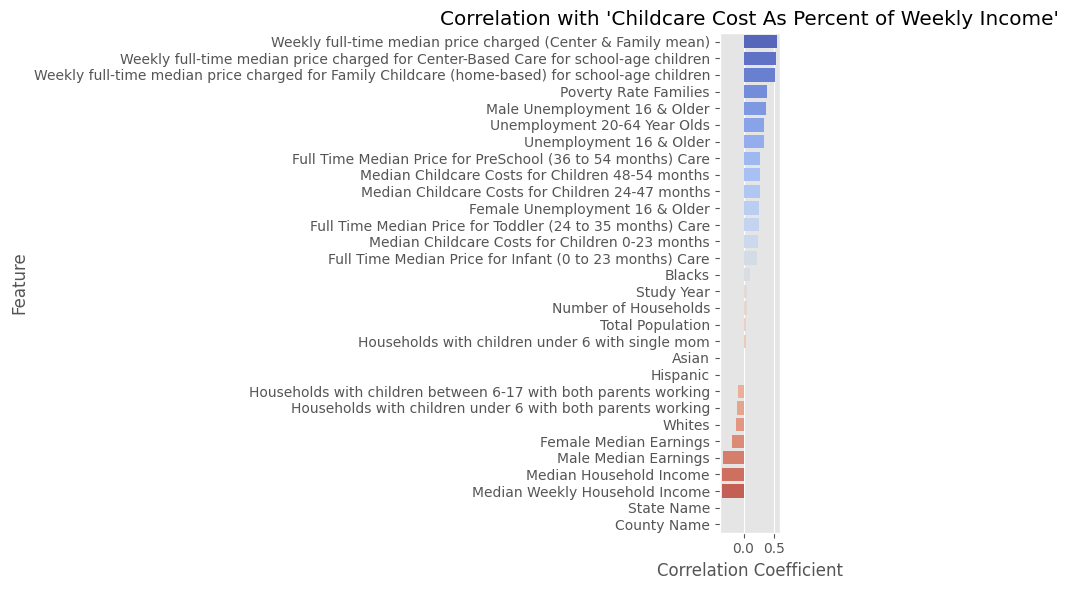

In [21]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

target_col = 'Childcare Cost As Percent of Weekly Income'

# ensure the target exists
if target_col not in df.columns:
    print(f"Column '{target_col}' not found in DataFrame.")
else:
    # coerce all numeric columns
    df_num = df.apply(pd.to_numeric, errors='coerce')

    # drop rows with NA in target or features
    df_num = df_num.dropna(subset=[target_col])

    # compute correlation with target only
    corr_with_target = df_num.corr()[target_col].drop(target_col).sort_values(ascending=False)

    # display correlations
    print("Correlation with 'Childcare Cost As Percent of Weekly Income':")
    print(corr_with_target)

    # plot as bar chart
    plt.figure(figsize=(8, 6))
    sns.barplot(
        x=corr_with_target.values,
        y=corr_with_target.index,
        palette='coolwarm'
    )
    plt.title("Correlation with 'Childcare Cost As Percent of Weekly Income'")
    plt.xlabel("Correlation Coefficient")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()

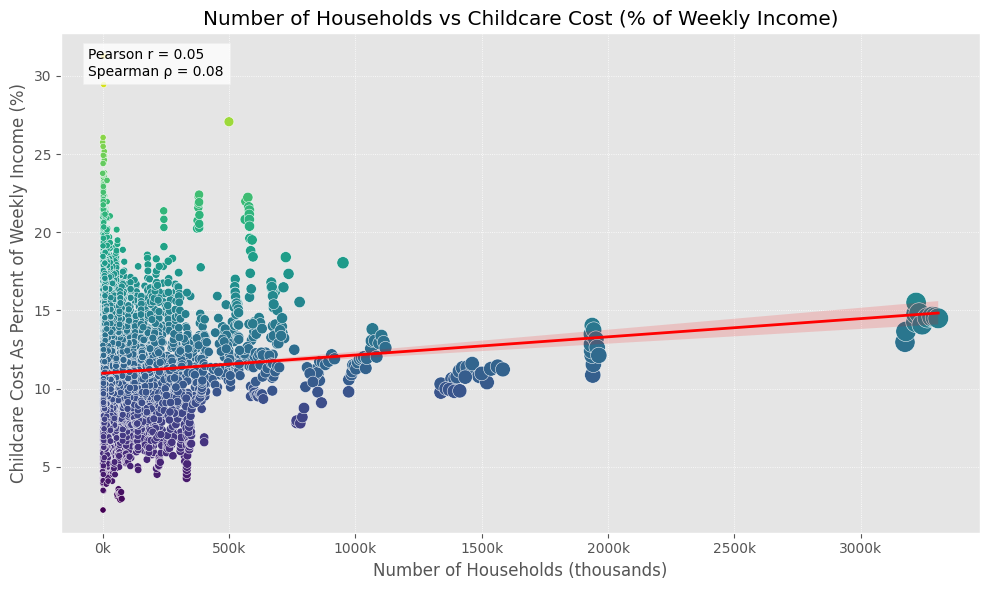

In [22]:
# Scatter: Number of Households vs Childcare Cost As Percent of Weekly Income
x = 'Number of Households'
y = childcare_pct_col  # 'Childcare Cost As Percent of Weekly Income'

# prepare numeric clean data
df_scatter = df[[x, y]].copy()
df_scatter[x] = pd.to_numeric(df_scatter[x], errors='coerce')
df_scatter[y] = pd.to_numeric(df_scatter[y], errors='coerce')
df_scatter = df_scatter.dropna()

if df_scatter.empty:
    print("No data available to plot.")
else:
    fig, ax = plt.subplots(figsize=(10, 6))
    # scatter with size proportional to households and color by childcare %
    sns.scatterplot(
        data=df_scatter,
        x=x, y=y,
        size=x, sizes=(20, 220),
        hue=y, palette='viridis',
        legend=False, ax=ax
    )

    # add a linear regression line (fit on the raw data)
    sns.regplot(data=df_scatter, x=x, y=y, scatter=False, ax=ax, color='red', line_kws={'linewidth':2})

    # format x-axis ticks as thousands
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{int(x/1000)}k'))

    # annotate correlation coefficients
    pearson = df_scatter[x].corr(df_scatter[y])
    spearman = df_scatter[x].corr(df_scatter[y], method='spearman')
    ax.text(0.03, 0.97, f"Pearson r = {pearson:.2f}\nSpearman ρ = {spearman:.2f}",
            transform=ax.transAxes, va='top', bbox=dict(facecolor='white', alpha=0.8))

    ax.set_title('Number of Households vs Childcare Cost (% of Weekly Income)')
    ax.set_xlabel('Number of Households (thousands)')
    ax.set_ylabel('Childcare Cost As Percent of Weekly Income (%)')
    ax.grid(True, linestyle=':', linewidth=0.6)
    plt.tight_layout()
    plt.show()

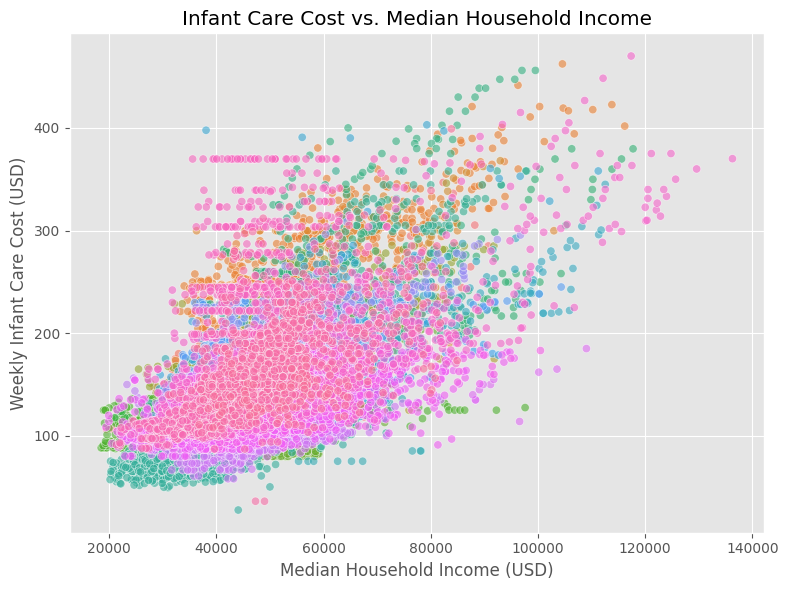

In [23]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df,
    x="Median Household Income",
    y="Full Time Median Price for Infant (0 to 23 months) Care",
    hue="State Name",
    alpha=0.6,
    legend=False
)
plt.title("Infant Care Cost vs. Median Household Income")
plt.xlabel("Median Household Income (USD)")
plt.ylabel("Weekly Infant Care Cost (USD)")
plt.tight_layout()
plt.show()

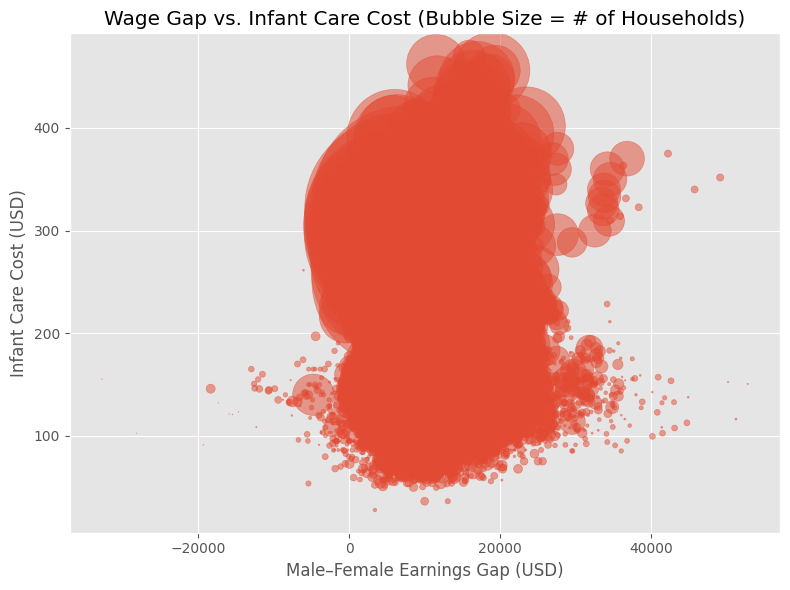

In [24]:
df["Wage Gap"] = df["Male Median Earnings"] - df["Female Median Earnings"]

plt.figure(figsize=(8, 6))
plt.scatter(
    df["Wage Gap"],
    df["Full Time Median Price for Infant (0 to 23 months) Care"],
    s=df["Number of Households"] / 200,
    alpha=0.5
)
plt.title("Wage Gap vs. Infant Care Cost (Bubble Size = # of Households)")
plt.xlabel("Male–Female Earnings Gap (USD)")
plt.ylabel("Infant Care Cost (USD)")
plt.tight_layout()
plt.show()

Features used: ['Weekly full-time median price charged (Center & Family mean)', 'Weekly full-time median price charged for Center-Based Care for school-age children', 'Weekly full-time median price charged for Family Childcare (home-based) for school-age children', 'Poverty Rate Families', 'Male Unemployment 16 & Older', 'Median Weekly Household Income', 'Median Household Income', 'Unemployment 20-64 Year Olds', 'Unemployment 16 & Older', 'Male Median Earnings']
Test RMSE: 0.2128, R^2: 0.9948

Feature importances:
Weekly full-time median price charged (Center & Family mean)                                       0.523620
Median Weekly Household Income                                                                     0.238129
Median Household Income                                                                            0.170725
Weekly full-time median price charged for Center-Based Care for school-age children                0.057045
Male Median Earnings                            

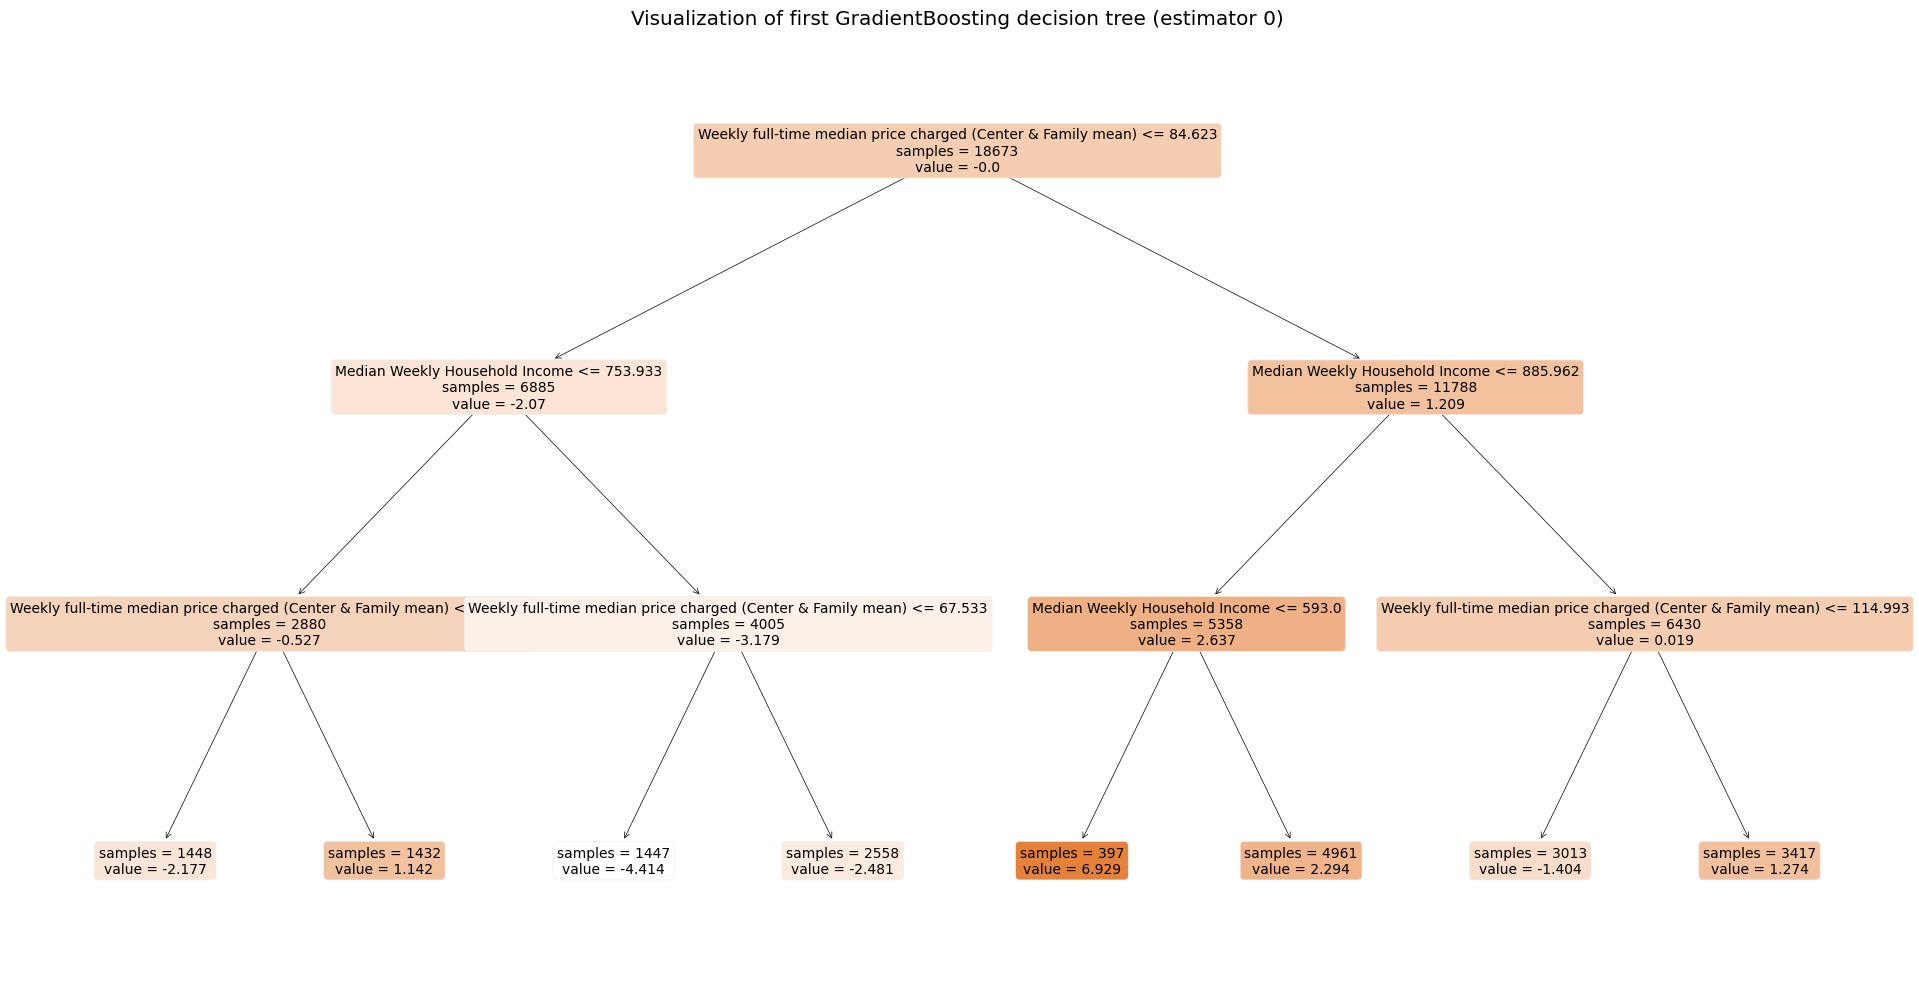

In [26]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.tree import export_text
from sklearn.metrics import mean_squared_error, r2_score

# Gradient Boosting analysis and print a single decision tree

# use existing variables: df, corr_with_target, target_col
target = target_col  # 'Childcare Cost As Percent of Weekly Income'

# choose candidate features: prefer precomputed correlations if available
if 'corr_with_target' in globals() and isinstance(corr_with_target, (pd.Series,)):
    # take top numeric features by absolute correlation (exclude the target itself)
    feats = corr_with_target.drop(labels=[target], errors='ignore').dropna().abs().sort_values(ascending=False).head(10).index.tolist()
else:
    # fallback: top numeric columns excluding target and identifiers
    numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    feats = [c for c in numeric_cols if c != target][:10]

# ensure selected features exist in df
feats = [c for c in feats if c in df.columns]
print("Features used:", feats)

# prepare data (coerce to numeric and drop rows with NA in features/target)
X = df[feats].apply(pd.to_numeric, errors='coerce')
y = pd.to_numeric(df[target], errors='coerce')
data = pd.concat([X, y], axis=1).dropna()
X_clean = data[feats]
y_clean = data[target]

# train/test split
X_train, X_test, y_train, y_test = train_test_split(X_clean, y_clean, test_size=0.2, random_state=42)

# fit Gradient Boosting Regressor
gbr = GradientBoostingRegressor(n_estimators=100, max_depth=3, random_state=42)
gbr.fit(X_train, y_train)

# evaluate
y_pred = gbr.predict(X_test)
rmse = mean_squared_error(y_test, y_pred, squared=False)
r2 = r2_score(y_test, y_pred)
print(f"Test RMSE: {rmse:.4f}, R^2: {r2:.4f}")

# feature importances
importances = pd.Series(gbr.feature_importances_, index=feats).sort_values(ascending=False)
print("\nFeature importances:")
print(importances)

# export a single tree (the first estimator)
# estimators_ is shape (n_estimators, n_outputs); for single-output use estimators_[i, 0]
single_tree = gbr.estimators_[0, 0]
tree_text = export_text(single_tree, feature_names=feats, max_depth=5)
print("\nSingle decision tree (first estimator):")
print(tree_text)

# Visualize the single decision tree
from sklearn.tree import plot_tree

fig, ax = plt.subplots(figsize=(20, 10))
plot_tree(
    single_tree,
    feature_names=feats,
    filled=True,
    rounded=True,
    impurity=False,
    fontsize=10,
    ax=ax
)
ax.set_title('Visualization of first GradientBoosting decision tree (estimator 0)')
plt.tight_layout()
plt.show()